In [1]:
%matplotlib inline
import os
import sys
import torch
import numpy as np
from matplotlib import pyplot as plt
import cv2
import imageio
import time

In [2]:
sam2_path = '../../sam2_test/segment-anything-2-real-time/'

In [3]:
torch.autocast(device_type="cuda", dtype=torch.bfloat16).__enter__()

if torch.cuda.get_device_properties(0).major >= 8:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

In [4]:
sys.path.append(sam2_path)
from sam2.build_sam import build_sam2_camera_predictor #, build_sam2_video_predictor

In [5]:
sam2_checkpoint = os.path.join(sam2_path, "checkpoints/sam2_hiera_small.pt")
model_cfg = "sam2_hiera_s.yaml"

predictor = build_sam2_camera_predictor(model_cfg, sam2_checkpoint)

(0.0, 1.0, 0.0, 1.0)

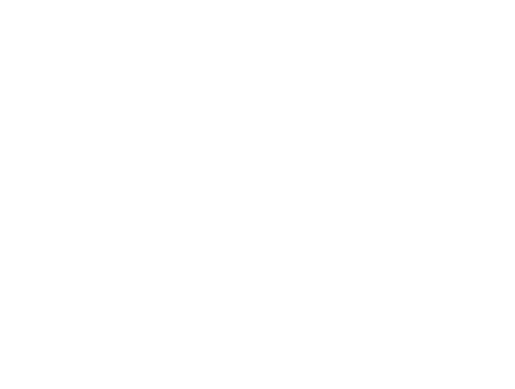

In [6]:
cap = cv2.VideoCapture("../01_rtsp_recording/output_stream_11.avi")

if_init = False
next_vid = True
vid_count = 1
frame_count = 1

frame_width = 1920
frame_height = 1080
plt.ion() 
fig, ax = plt.subplots()
ax.axis('off')

In [ ]:
while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    width, height = frame.shape[:2][::-1]

    if not if_init:
        predictor.load_first_frame(frame)
        if_init = True

        ann_frame_idx = 0 
        ann_obj_id = 1
        
        bbox = np.array([[1750, 950], [1880, 1030]], dtype=np.float32)
        _, out_obj_ids, out_mask_logits = predictor.add_new_prompt(
            frame_idx=ann_frame_idx, obj_id=ann_obj_id, bbox=bbox
        )

    else:
        out_obj_ids, out_mask_logits = predictor.track(frame)

        all_mask = np.zeros((height, width, 1), dtype=np.uint8)
        # print(all_mask.shape)
        for i in range(0, len(out_obj_ids)):
            out_mask = (out_mask_logits[i] > 0.0).permute(1, 2, 0).cpu().numpy().astype(
                np.uint8
            ) * 255

            all_mask = cv2.bitwise_or(all_mask, out_mask)

        all_mask = cv2.cvtColor(all_mask, cv2.COLOR_GRAY2RGB)
        frame = cv2.addWeighted(frame, 1, all_mask, 0.5, 0)